<a href="https://colab.research.google.com/github/MJMortensonWarwick/AnalyticsEngineering2026/blob/main/2_03_practice_bike_hire_student.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

![](https://drive.google.com/uc?export=view&id=17M9oGaOj4KdKiDDH3oTibxJ9qBTSjp6n)

# 2.03 Practice session
## Bike-hire trips

## How this practice works

This is a **short rehearsal** of the timed test. You do not need to finish or get the "right" answer. The aim is to practise the way of working.

- You have about **45 minutes**. Work individually.
- You may use **any AI tool** (for example Gemini in Colab). We are **not marking** anything today. In the real test, the quality of AI-generated code will not matter. What matters is the control youDshow.
- Write in markdown cells as you go: your thinking, **each prompt you send (paste it as you send it)**, and the checks you make.
- Unfinished work is fine. Say what you did not get to.
- At the end, download the Notebook (using File > Download > Download .ipynb). Once it has completed please zip the file up. This is the artefact you would submit for the in-class test.
- You can also save a copy to your GitHub using the instructions from my.wbs (1b asychronous tasks).

**Suggested timing**

| Minutes | Focus |
| --- | --- |
| 0 to 10 | Look at the tables and note what you find |
| 10 to 25 | Clean and prepare the data |
| 25 to 38 | Join and aggregate to answer the question |
| 38 to 45 | Check your answer and write up |

At the end, use **Runtime, then Restart session and run all** and note anything that fails.


## The data

A fictional bike-hire scheme: three tables covering trips taken in March 2025.

| Table | What it holds |
| --- | --- |
| `trips` | One record per trip: bike, start and end station, start time, duration and user type |
| `bikes` | The bikes, with type and purchase year |
| `stations` | The docking stations, with zone and capacity |

**How they connect:** `trips.bike_id` to `bikes.bike_id`, and `trips.start_station_id` (and `end_station_id`) to `stations.station_id`.

Check the real column names in the next cell before you write anything.


In [1]:
# ---- Setup: run this cell first ----
!pip install -q duckdb

import glob
import os

import duckdb
import pandas as pd

DATA_URL = "https://github.com/MJMortensonWarwick/adminaeaiv/releases/download/dbsession/bike-hire-practice.zip"

DATA_DIR = "/content/bikes"
# Download only if no CSV files are there yet. The CSVs may sit inside a folder
# within the zip; the search below looks in sub-folders too.
if DATA_URL and not glob.glob(os.path.join(DATA_DIR, "**", "*.csv"), recursive=True):
    import urllib.request
    import zipfile
    os.makedirs(DATA_DIR, exist_ok=True)
    urllib.request.urlretrieve(DATA_URL, "/content/bikes.zip")
    zipfile.ZipFile("/content/bikes.zip").extractall(DATA_DIR)

FILES = {"trips": "trips.csv", "bikes": "bikes.csv", "stations": "stations.csv"}

tables, missing = {}, []
for name, filename in FILES.items():
    found = glob.glob(os.path.join(DATA_DIR, "**", filename), recursive=True)
    if found:
        tables[name] = pd.read_csv(found[0])
    else:
        missing.append(filename)

if missing:
    found_csvs = sorted(os.path.basename(f) for f in glob.glob(os.path.join(DATA_DIR, "**", "*.csv"), recursive=True))
    raise FileNotFoundError(
        f"Missing files: {missing}. CSV files found under {DATA_DIR}: {found_csvs}. Ask for help."
    )

# Make every table available as a DuckDB table, so you can use SQL or pandas.
con = duckdb.connect()
for name, df in tables.items():
    con.register(name, df)


def q(sql):
    """Run SQL against the tables above and return a pandas DataFrame."""
    return con.sql(sql).df()


for name, df in tables.items():
    print(f"{name}: {df.shape[0]:,} rows, {df.shape[1]} columns")
    print("   ", list(df.columns))


trips: 612 rows, 7 columns
    ['trip_id', 'bike_id', 'start_station_id', 'end_station_id', 'start_time', 'duration_min', 'user_type']
bikes: 60 rows, 3 columns
    ['bike_id', 'bike_type', 'purchase_year']
stations: 12 rows, 4 columns
    ['station_id', 'station_name', 'zone', 'capacity']


## Examples: two ways to work with the tables

You can use SQL, pandas, or a mix of both. The next two cells show each. Run them and change them to see what happens. You do not have to use them in your answer.


In [2]:
# Example 1: SQL
# q() runs SQL against any of the tables above and returns a pandas DataFrame.
from IPython.display import display

display(q("SELECT * FROM trips LIMIT 5"))

display(q("SELECT COUNT(*) AS n_rows, COUNT(DISTINCT trip_id) AS n_distinct_trips FROM trips"))

display(q("""
    SELECT t.trip_id, s.station_name
    FROM trips AS t
    JOIN stations AS s ON t.start_station_id = s.station_id
    LIMIT 5
"""))


,trip_id,bike_id,start_station_id,end_station_id,start_time,duration_min,user_type
0,T0001,B028,S05,S01,2025-03-01 05:52:00,21.0,Casual
1,T0002,B043,S12,S12,2025-03-01 06:31:00,27.0,CASUAL
2,T0003,B045,S11,S07,2025-03-01 07:06:00,18.0,Casual
3,T0004,B051,S04,S04,2025-03-01 07:06:00,34.0,Member
4,T0005,B049,S01,S09,2025-03-01 07:36:00,16.0,Member


,n_rows,n_distinct_trips
0,612,600


,trip_id,station_name
0,T0001,Park Road
1,T0002,Cathedral Close
2,T0003,Sports Centre
3,T0004,University Gate
4,T0005,Market Square


In [3]:
# Example 2: pandas
# Each table is also a pandas DataFrame, stored in the dictionary `tables`.
from IPython.display import display

trips = tables["trips"]
display(trips.head())
print(trips.shape)
print(trips.dtypes)

joined = tables["trips"].merge(tables["stations"], left_on="start_station_id", right_on="station_id", how="inner")
display(joined[["trip_id", "station_name"]].head())

# You can mix the two: run SQL, then use pandas methods on the result
result = q("SELECT start_station_id FROM trips")
print(result["start_station_id"].nunique(), "different start stations in trips")


,trip_id,bike_id,start_station_id,end_station_id,start_time,duration_min,user_type
0,T0001,B028,S05,S01,2025-03-01 05:52:00,21.0,Casual
1,T0002,B043,S12,S12,2025-03-01 06:31:00,27.0,CASUAL
2,T0003,B045,S11,S07,2025-03-01 07:06:00,18.0,Casual
3,T0004,B051,S04,S04,2025-03-01 07:06:00,34.0,Member
4,T0005,B049,S01,S09,2025-03-01 07:36:00,16.0,Member


(612, 7)
trip_id                 str
bike_id                 str
start_station_id        str
end_station_id          str
start_time              str
duration_min        float64
user_type               str
dtype: object


,trip_id,station_name
0,T0001,Park Road
1,T0002,Cathedral Close
2,T0003,Sports Centre
3,T0004,University Gate
4,T0005,Market Square


12 different start stations in trips


## Your brief

**From:** the scheme manager

> We want to know whether electric bikes are used for longer trips than standard bikes, and whether that differs by zone. Please give us the **average trip duration by bike type and by the zone of the start station**.

![](https://drive.google.com/uc?export=view&id=1eH5Q3l4LnzwZ-XcT_kJDeHoKA2rufiOW)

**What your final table should look like**

One row per combination of bike type and zone, with the number of trips and the average duration in minutes. State what one row represents.

**Things to think about** (you do not have to solve all of them)

- Are there missing, duplicated or odd values in the tables you use? What will you do about each, and why?
- Do the bike types and dates look consistent?
- How will you check your final table is believable?


## Summary for the scheme manager
*(Written at the end, placed here so it's the first thing you read.)*

**Short answer: no. In March 2025, electric bikes were used for *shorter* trips than standard bikes, not longer ones.**

- After cleaning, the average electric trip was **14.8 minutes** against **19.3 minutes** on a standard bike (567 usable trips).
- The gap holds in **every zone**: electric trips are between about 4 and 6 minutes shorter wherever they start. The zone matters much less than the bike type.
- The gap is not explained by who rides them. Members and casual users split the same way on both bike types (roughly 63/37), and the gap appears for both groups.

**One important caveat:** we measure *time*, not *distance*. E-bikes are faster, so a shorter trip may cover the same ground or more. If the real question is "do e-bikes get used for longer journeys", we need trip distance or end-station coordinates. That would be my first recommendation.

**Data decisions that moved the answer:** I removed 12 duplicated trips and excluded 3 trips logged at exactly 1 or 2 days (almost certainly bikes not docked properly). Left in, those three trips would push the standard-bike average from 19 to 33 minutes and make the gap look about four times bigger than it really is. 30 trips had no duration recorded and are excluded from the averages. Electric trips starting in the East are based on only 11 trips, so treat that cell as indicative.

The full table is in Section 3 and the checks are in Section 4.

## 1. Look at the data

**What I need for the brief:** `duration_min` from trips, `bike_type` from bikes and `zone` from stations (via the *start* station). The answer's grain is **bike type × start zone**, so at most 2 × 5 = 10 rows if the categories are clean.

Before cleaning anything I want to know three things about each table: what one row represents, whether the key is really unique, and whether the columns I need are complete and consistent.

In [4]:
# What does one row represent? Check each table's key is actually unique.
from IPython.display import display

trips_raw = tables["trips"].copy()
bikes_raw = tables["bikes"].copy()
stations_raw = tables["stations"].copy()

for name, df, key in [("trips", trips_raw, "trip_id"),
                      ("bikes", bikes_raw, "bike_id"),
                      ("stations", stations_raw, "station_id")]:
    print(f"{name:9s} rows={len(df):4d}  distinct {key}={df[key].nunique():4d}  "
          f"key unique? {df[key].is_unique}")

trips     rows= 612  distinct trip_id= 600  key unique? False
bikes     rows=  60  distinct bike_id=  60  key unique? True
stations  rows=  12  distinct station_id=  12  key unique? True


Bikes and stations are clean at the key level: one row per bike, one row per station. **Trips is not.** There are 612 rows but only 600 trip IDs, so something is repeated. I'll look at that below.

In [5]:
# Missing values per column
for name, df in [("trips", trips_raw), ("bikes", bikes_raw), ("stations", stations_raw)]:
    nulls = df.isna().sum()
    print(name, "->", nulls[nulls > 0].to_dict() or "no nulls")

trips -> {'duration_min': 30}
bikes -> no nulls
stations -> {'capacity': 1}


In [6]:
# Text categories. Printing with repr() so trailing spaces become visible.
print("bike_type :", [repr(v) for v in bikes_raw["bike_type"].unique()])
print("zone      :", [repr(v) for v in stations_raw["zone"].unique()])
print("user_type :", [repr(v) for v in trips_raw["user_type"].unique()])
print()
display(bikes_raw["bike_type"].value_counts().rename("bikes"))

bike_type : ["'Standard'", "'Electric '", "'electric'", "'STANDARD'", "'standard'", "'Electric'", "'E-bike'"]
zone      : ["'Centre'", "'North'", "'West'", "'South'", "'East'"]
user_type : ["'Casual'", "'CASUAL'", "'Member'", "'MEMBER'", "'Casual '", "'member'", "'casual'"]



bike_type
Standard     36
Electric      9
STANDARD      8
standard      3
Electric      2
electric      1
E-bike        1
Name: bikes, dtype: int64

`bike_type` is a mess: seven spellings for what should be two categories ("Electric " has a trailing space, "E-bike" appears once). If I grouped on this as-is I'd get seven "bike types". `zone` is clean. `user_type` has the same casing problem but isn't needed for the brief.

In [7]:
# Durations: range and the extreme values
display(trips_raw["duration_min"].describe().round(1).to_frame().T)
print("Largest 8 durations :", sorted(trips_raw["duration_min"].dropna())[-8:])
print("Smallest 5 durations:", sorted(trips_raw["duration_min"].dropna())[:5])

,count,mean,std,min,25%,50%,75%,max
duration_min,582.0,27.9,145.1,4.0,12.0,16.0,22.0,2880.0


Largest 8 durations : [51.0, 52.0, 52.0, 67.0, 90.0, 1440.0, 1440.0, 2880.0]
Smallest 5 durations: [4.0, 4.0, 4.0, 5.0, 5.0]


The median is 16 minutes, but the mean is 28 and the max is 2,880. Three values (1,440, 1,440 and 2,880) are exactly 1 and 2 days. After 90 minutes there is nothing until 1,440, so these are not a natural tail. They look like system artefacts, such as a bike not docked properly or a trip closed by an overnight job. No zero or negative durations.

In [8]:
# Duplicates: are the repeated trip_ids exact copies, or different trips sharing an ID?
dup_ids = trips_raw[trips_raw["trip_id"].duplicated(keep=False)]
print("rows involved in repeated trip_ids:", len(dup_ids))
print("fully identical duplicate rows    :", trips_raw.duplicated().sum())
display(dup_ids.sort_values("trip_id").head(6))

rows involved in repeated trip_ids: 24
fully identical duplicate rows    : 12


,trip_id,bike_id,start_station_id,end_station_id,start_time,duration_min,user_type
96,T0097,B031,S12,S12,2025-03-06 08:14:00,10.0,Casual
97,T0097,B031,S12,S12,2025-03-06 08:14:00,10.0,Casual
175,T0175,B059,S04,S09,2025-03-09 21:51:00,13.0,Casual
176,T0175,B059,S04,S09,2025-03-09 21:51:00,13.0,Casual
185,T0184,B034,S02,S03,2025-03-10 12:23:00,25.0,Casual
186,T0184,B034,S02,S03,2025-03-10 12:23:00,25.0,Casual


All 12 extra rows are **exact** copies, the same in every column. That points to a double load in the export rather than two different trips sharing an ID, so dropping them is safe.

In [9]:
# Dates: how many formats are in start_time?
iso_like = trips_raw["start_time"].str.match(r"^\d{4}-\d{2}-\d{2}")
uk_like = trips_raw["start_time"].str.match(r"^\d{2}/\d{2}/\d{4}")
print("ISO 'YYYY-MM-DD hh:mm:ss':", iso_like.sum())
print("UK  'DD/MM/YYYY hh:mm'   :", uk_like.sum())
print("neither                  :", (~iso_like & ~uk_like).sum())
print(trips_raw.loc[uk_like, "start_time"].head(3).tolist())

ISO 'YYYY-MM-DD hh:mm:ss': 514
UK  'DD/MM/YYYY hh:mm'   : 98
neither                  : 0
['01/03/2025 09:26', '01/03/2025 18:43', '01/03/2025 19:16']


In [10]:
# Referential integrity: does every trip point at a bike and a station that exist?
print("bike_ids in trips not in bikes      :", set(trips_raw["bike_id"]) - set(bikes_raw["bike_id"]))
print("start stations not in stations      :", set(trips_raw["start_station_id"]) - set(stations_raw["station_id"]))
print("end stations not in stations        :", set(trips_raw["end_station_id"]) - set(stations_raw["station_id"]))

bike_ids in trips not in bikes      : set()
start stations not in stations      : set()
end stations not in stations        : set()


### What I found, and what I plan to do about it

| # | Issue | Table | Affects the answer? | Plan |
|---|---|---|---|---|
| 1 | 12 exact duplicate trip rows (612 rows, 600 trips) | trips | **Yes**: double counts trips | Drop exact duplicates |
| 2 | 7 spellings of bike type, including trailing spaces and "E-bike" | bikes | **Yes**: breaks the grouping | Trim, lowercase, map "e-bike" to electric (an assumption) |
| 3 | 3 durations of exactly 1,440 / 2,880 min | trips | **Yes**: distorts averages badly | Exclude with an explicit business rule, not a statistical one |
| 4 | 30 missing durations | trips | **Yes**: can't average a blank | Exclude from averages, report how many |
| 5 | Two date formats (ISO and UK day-first) | trips | No, not for this question | Parse both explicitly, check everything falls in March 2025 |
| 6 | user_type casing | trips | No | Quick tidy, useful for one sanity check |
| 7 | One station with missing capacity (Old Town Hall) | stations | No | Leave it, note it |

Good news: every trip links to a known bike and a known station, so the joins shouldn't lose rows.

## 2. Clean and prepare

I'm keeping the raw tables untouched and working on copies, so any step can be re-run or undone. One fix per cell, with a row count after each.

In [11]:
# Fix 1: drop exact duplicate trips
trips = trips_raw.drop_duplicates().copy()
assert trips["trip_id"].is_unique, "trip_id still not unique - duplicates were not exact copies"
print(f"trips: {len(trips_raw)} -> {len(trips)} rows (removed {len(trips_raw) - len(trips)})")

trips: 612 -> 600 rows (removed 12)


In [12]:
# Fix 2: standardise bike_type to two categories
bikes = bikes_raw.copy()
cleaned = bikes["bike_type"].str.strip().str.lower()
mapping = {"standard": "Standard", "electric": "Electric", "e-bike": "Electric"}
bikes["bike_type_clean"] = cleaned.map(mapping)

assert bikes["bike_type_clean"].notna().all(), "an unmapped bike_type is left over"
display(pd.crosstab(bikes["bike_type"].map(repr), bikes["bike_type_clean"]))

bike_type_clean,Electric,Standard
bike_type,,
'E-bike',1,0
'Electric ',2,0
'Electric',9,0
'STANDARD',0,8
'Standard',0,36
'electric',1,0
'standard',0,3


Every original spelling now lands in one of two categories, and nothing is left unmapped (the assert would fail if a new spelling appeared). **Assumption:** "E-bike" (one bike, B038, bought in 2024) is an electric bike. That seems safe, but it's an assumption and I've noted it in Section 6. The fleet is now 47 standard and 13 electric.

In [13]:
# Fix 3: parse start_time explicitly - two known formats, no guessing
iso = pd.to_datetime(trips["start_time"], format="%Y-%m-%d %H:%M:%S", errors="coerce")
uk = pd.to_datetime(trips["start_time"], format="%d/%m/%Y %H:%M", errors="coerce")
trips["start_dt"] = iso.fillna(uk)

print("unparsed rows:", trips["start_dt"].isna().sum())
print("range:", trips["start_dt"].min(), "to", trips["start_dt"].max())

# Sanity check on the day-first assumption: read the UK rows month-first instead
uk_rows = trips["start_time"].str.contains("/")
alt = pd.to_datetime(trips.loc[uk_rows, "start_time"], format="%m/%d/%Y %H:%M", errors="coerce")
print("UK-format rows:", uk_rows.sum(),
      "| if read month-first, rows NOT in March 2025:", (alt.dt.month != 3).sum())

unparsed rows: 0
range: 2025-03-01 05:52:00 to 2025-03-31 21:54:00
UK-format rows: 97 | if read month-first, rows NOT in March 2025: 96


All 600 rows parse, and everything falls inside March 2025. That's what the brief says the data covers, which is a good sign. The check at the bottom matters: if I had read the slash dates month-first, almost all of them would land outside March (or fail to parse). So day-first is the right reading, not just a guess.

In [14]:
# Fix 4 (not needed for the brief, but cheap): tidy user_type
trips["user_type_clean"] = trips["user_type"].str.strip().str.title()
print(trips["user_type_clean"].value_counts().to_dict())

{'Member': 386, 'Casual': 214}


### Durations: choosing a rule

This is the decision that moves the answer most, so I want it to be deliberate.

- **Missing (30 trips):** I can't impute a trip length credibly, so these are excluded from the average and reported.
- **Implausible:** I'm using a **business rule: anything over 180 minutes (3 hours) is treated as a data error.** For a city docking scheme a 3-hour single trip is already generous. The data has a clean gap between 90 and 1,440 minutes, so any threshold from about 2 to 23 hours gives the same result.

I considered a standard statistical rule (1.5 × IQR) and rejected it. The cell below shows why.

In [15]:
MAX_PLAUSIBLE_MIN = 180   # business rule - change here if the scheme has a different policy

d = trips["duration_min"].dropna()
q1, q3 = d.quantile([0.25, 0.75])
iqr_cut = q3 + 1.5 * (q3 - q1)
print(f"IQR rule would cut at {iqr_cut:.0f} min and drop {(d > iqr_cut).sum()} trips")
print(f"Business rule cuts at {MAX_PLAUSIBLE_MIN} min and drops {(d > MAX_PLAUSIBLE_MIN).sum()} trips")
print("Trips between the two cut-offs:", sorted(d[(d > iqr_cut) & (d <= MAX_PLAUSIBLE_MIN)].tolist()))

IQR rule would cut at 37 min and drop 19 trips
Business rule cuts at 180 min and drops 3 trips
Trips between the two cut-offs: [39.0, 39.0, 40.0, 40.0, 40.0, 40.0, 41.0, 41.0, 41.0, 46.0, 46.0, 50.0, 51.0, 52.0, 67.0, 90.0]


The IQR rule would throw away 19 trips. Only 3 of them are the broken records; the other 16 are rides of 39 to 90 minutes, which are perfectly believable leisure trips. That would bias the average downward. The real problem is three obviously broken records, not a long tail, so the business rule is the better tool.

In [16]:
# Flag rather than delete, so the exclusions stay visible and countable
import numpy as np

trips["duration_status"] = np.select(
    [trips["duration_min"].isna(), trips["duration_min"] > MAX_PLAUSIBLE_MIN],
    ["missing", "implausible"],
    default="ok",
)
print(trips["duration_status"].value_counts().to_dict())
display(trips.loc[trips["duration_status"] == "implausible",
                  ["trip_id", "bike_id", "start_station_id", "end_station_id", "start_dt", "duration_min"]])

{'ok': 567, 'missing': 30, 'implausible': 3}


,trip_id,bike_id,start_station_id,end_station_id,start_dt,duration_min
80,T0081,B010,S12,S11,2025-03-04 21:57:00,2880.0
143,T0143,B020,S09,S10,2025-03-08 12:23:00,1440.0
287,T0284,B046,S08,S03,2025-03-15 20:25:00,1440.0


## 3. Join and aggregate

**Expected row counts before I run anything:**
- trips (600) → join bikes on `bike_id`: still **600**. Each trip has one bike, so this is many-to-one and shouldn't add rows.
- → join stations on `start_station_id`: still **600**, for the same reason.

If either number changes, a key is duplicated somewhere and the averages would be wrong. `validate="many_to_one"` makes pandas stop if that happens, and the asserts check the count.

In [17]:
trip_bike = trips.merge(
    bikes[["bike_id", "bike_type_clean"]],
    on="bike_id", how="left", validate="many_to_one",
)
assert len(trip_bike) == len(trips)
print("after joining bikes   :", len(trip_bike))

trip_full = trip_bike.merge(
    stations_raw[["station_id", "station_name", "zone"]],
    left_on="start_station_id", right_on="station_id", how="left", validate="many_to_one",
)
assert len(trip_full) == len(trips)
print("after joining stations:", len(trip_full))

# A left join would quietly leave blanks if a key failed to match - check there are none
print("trips with no bike type:", trip_full["bike_type_clean"].isna().sum(),
      "| trips with no zone:", trip_full["zone"].isna().sum())

after joining bikes   : 600
after joining stations: 600
trips with no bike type: 0 | trips with no zone: 0


In [18]:
# The answer table: one row per bike type x start zone
usable = trip_full[trip_full["duration_status"] == "ok"]

result = (
    usable.groupby(["bike_type_clean", "zone"])
    .agg(n_trips=("trip_id", "count"),
         avg_duration_min=("duration_min", "mean"),
         median_duration_min=("duration_min", "median"))
    .round(1)
)

# Show what was left out of each cell, so the reader can see the denominator
excluded = (trip_full[trip_full["duration_status"] != "ok"]
            .groupby(["bike_type_clean", "zone"]).size().rename("n_excluded"))
result = result.join(excluded).fillna({"n_excluded": 0}).astype({"n_excluded": int})

result = result.reset_index().rename(columns={"bike_type_clean": "bike_type"})
display(result)

,bike_type,zone,n_trips,avg_duration_min,median_duration_min,n_excluded
0,Electric,Centre,81,14.5,13.0,6
1,Electric,East,11,15.7,18.0,1
2,Electric,North,23,16.0,15.0,1
3,Electric,South,24,13.4,12.0,2
4,Electric,West,22,15.7,12.5,3
5,Standard,Centre,215,18.9,17.0,12
6,Standard,East,20,19.5,16.5,4
7,Standard,North,39,20.4,17.0,0
8,Standard,South,59,19.5,16.0,1
9,Standard,West,73,19.8,18.0,3


**What one row represents:** all usable trips in March 2025 for one bike type starting in one zone. `n_trips` is the number of trips the average is based on. `n_excluded` shows trips in that group that were dropped for a missing or implausible duration.

I've added the median alongside the mean because durations are skewed. Where the two are close, the average isn't being driven by a handful of long rides. I kept `n_trips` as the count *used in the average*, not all trips. Otherwise the count and the mean would describe different populations, which is an easy trap to fall into.

In [19]:
# Easier to read side by side: does the electric vs standard gap change by zone?
wide = result.pivot(index="zone", columns="bike_type", values="avg_duration_min")
wide["electric_minus_standard"] = (wide["Electric"] - wide["Standard"]).round(1)
wide["electric_trips"] = result[result["bike_type"] == "Electric"].set_index("zone")["n_trips"]
display(wide)

overall = (usable.groupby("bike_type_clean")["duration_min"]
           .agg(n_trips="count", avg_duration_min="mean", median_duration_min="median").round(1))
display(overall)

bike_type,Electric,Standard,electric_minus_standard,electric_trips
zone,,,,
Centre,14.5,18.9,-4.4,81
East,15.7,19.5,-3.8,11
North,16.0,20.4,-4.4,23
South,13.4,19.5,-6.1,24
West,15.7,19.8,-4.1,22


,n_trips,avg_duration_min,median_duration_min
bike_type_clean,,,
Electric,161,14.8,13.0
Standard,406,19.3,17.0


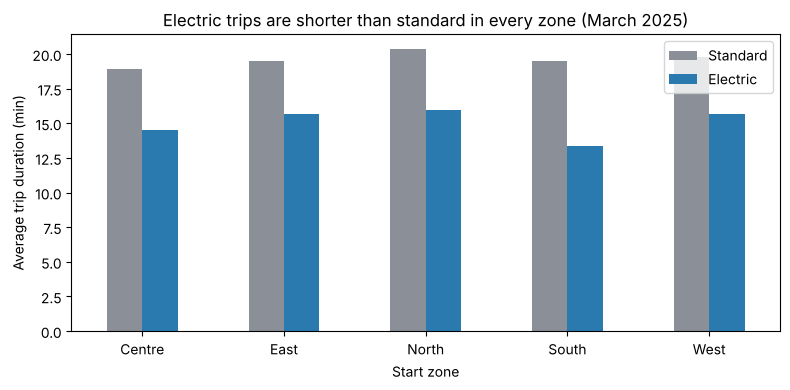

In [20]:
import matplotlib.pyplot as plt

ax = wide[["Standard", "Electric"]].plot(kind="bar", figsize=(8, 4), color=["#8a8f98", "#2a7ab0"])
ax.set_ylabel("Average trip duration (min)")
ax.set_xlabel("Start zone")
ax.set_title("Electric trips are shorter than standard in every zone (March 2025)")
ax.legend(title="")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

The pattern is consistent: electric trips are shorter everywhere, by roughly 4 to 6 minutes, with the biggest gap in the South. The zone itself makes little difference. Standard averages sit at about 19–20 minutes in every zone, and electric at 13–16.

## 4. Check

Four checks: does the table reconcile to the trip count, does an independent method give the same numbers, does one cell hold up by hand, and how sensitive is the answer to my cleaning decisions.

In [21]:
# Check 1: reconciliation. Every one of the 600 trips is either in the table or excluded.
in_table = result["n_trips"].sum()
excl = result["n_excluded"].sum()
print(f"in table {in_table} + excluded {excl} = {in_table + excl}  (expected {len(trips)})")
assert in_table + excl == len(trips)
print("excluded breakdown:", trips["duration_status"].value_counts().to_dict())

in table 567 + excluded 33 = 600  (expected 600)
excluded breakdown: {'ok': 567, 'missing': 30, 'implausible': 3}


In [22]:
# Check 2: recompute the whole table in SQL, starting from the RAW tables,
# applying the same rules independently, and compare with the pandas result.
sql_result = q(f"""
    WITH t AS (SELECT DISTINCT * FROM trips),
         b AS (
            SELECT bike_id,
                   CASE WHEN lower(trim(bike_type)) IN ('electric', 'e-bike') THEN 'Electric'
                        WHEN lower(trim(bike_type)) = 'standard' THEN 'Standard' END AS bike_type
            FROM bikes)
    SELECT b.bike_type, s.zone,
           COUNT(*)                         AS n_trips,
           ROUND(AVG(t.duration_min), 1)    AS avg_duration_min
    FROM t
    JOIN b ON t.bike_id = b.bike_id
    JOIN stations s ON t.start_station_id = s.station_id
    WHERE t.duration_min IS NOT NULL AND t.duration_min <= {MAX_PLAUSIBLE_MIN}
    GROUP BY 1, 2
    ORDER BY 1, 2
""")

compare = result.merge(sql_result, on=["bike_type", "zone"], suffixes=("_pandas", "_sql"))
compare["match"] = (compare["n_trips_pandas"] == compare["n_trips_sql"]) & \
                   (compare["avg_duration_min_pandas"] == compare["avg_duration_min_sql"])
display(compare[["bike_type", "zone", "n_trips_pandas", "n_trips_sql",
                 "avg_duration_min_pandas", "avg_duration_min_sql", "match"]])
print("all rows match:", compare["match"].all(), "| rows compared:", len(compare))

,bike_type,zone,n_trips_pandas,n_trips_sql,avg_duration_min_pandas,avg_duration_min_sql,match
0,Electric,Centre,81,81,14.5,14.5,True
1,Electric,East,11,11,15.7,15.7,True
2,Electric,North,23,23,16.0,16.0,True
3,Electric,South,24,24,13.4,13.4,True
4,Electric,West,22,22,15.7,15.7,True
5,Standard,Centre,215,215,18.9,18.9,True
6,Standard,East,20,20,19.5,19.5,True
7,Standard,North,39,39,20.4,20.4,True
8,Standard,South,59,59,19.5,19.5,True
9,Standard,West,73,73,19.8,19.8,True


all rows match: True | rows compared: 10


In [23]:
# Check 3: spot check the smallest cell by hand - Electric trips starting in the East
east_e = usable[(usable["bike_type_clean"] == "Electric") & (usable["zone"] == "East")]
print("stations in East:", stations_raw.loc[stations_raw["zone"] == "East", "station_name"].tolist())
print("durations:", sorted(east_e["duration_min"].tolist()))
print(f"n = {len(east_e)}, sum = {east_e['duration_min'].sum():.0f}, "
      f"mean = {east_e['duration_min'].sum() / len(east_e):.1f}")

stations in East: ['Hospital Entrance']
durations: [5.0, 6.0, 7.0, 12.0, 14.0, 18.0, 19.0, 20.0, 21.0, 22.0, 29.0]
n = 11, sum = 173, mean = 15.7


In [24]:
# Check 4: sensitivity - what if I had NOT cleaned?
naive = trips_raw.merge(bikes_raw, on="bike_id").groupby("bike_type")["duration_min"].agg(["count", "mean"]).round(1)
print("Fully naive (raw bike types, duplicates, outliers kept):")
display(naive)

keep_outliers = (trip_full[trip_full["duration_status"] != "missing"]
                 .groupby("bike_type_clean")["duration_min"].agg(["count", "mean"]).round(1))
print("Clean categories and no duplicates, but the 3 implausible trips kept:")
display(keep_outliers)

Fully naive (raw bike types, duplicates, outliers kept):


,count,mean
bike_type,,
E-bike,11,15.5
Electric,113,14.8
Electric,31,15.3
STANDARD,68,20.5
Standard,322,36.9
electric,10,11.7
standard,27,19.3


Clean categories and no duplicates, but the 3 implausible trips kept:


,count,mean
bike_type_clean,,
Electric,161,14.8
Standard,409,33.3


**What the checks tell me:**

1. **Reconciles.** 567 trips in the table plus 33 excluded (30 missing, 3 implausible) = 600. Nothing has been lost or double counted in the joins.
2. **Independent recalculation matches.** The SQL version, built from the raw tables with the same rules, gives identical counts and averages in all 10 cells. The pandas logic isn't hiding a mistake.
3. **Spot check holds.** The East/Electric figure recalculates by hand from its 11 trips. It's also the weakest cell: one station, 11 trips.
4. **The cleaning matters a lot.** With raw data you get seven "bike types". Keeping just the three broken trips (all on standard bikes) pushes the standard average to about 33 minutes. That would make the gap look about four times bigger than it is, for entirely the wrong reason.

Is the result believable? Shorter electric trips make sense: e-bikes are faster, so the same journey takes less time. Electric bikes are 22% of the fleet (13 of 60) and carry 28% of usable trips (161 of 567), so they're being used a bit more intensively than standard bikes. Nothing here looks off.

In [25]:
# One more cut, beyond the brief: is the gap just a user-mix effect?
# If e-bikes were mostly used by members (who might take shorter commuter trips), that could explain it.
mix = pd.crosstab(usable["bike_type_clean"], usable["user_type_clean"], normalize="index").round(2)
display(mix)
display(usable.groupby(["bike_type_clean", "user_type_clean"])["duration_min"]
        .agg(n_trips="count", avg_duration_min="mean").round(1))

user_type_clean,Casual,Member
bike_type_clean,,
Electric,0.37,0.63
Standard,0.36,0.64


n_trips  avg_duration_min
bike_type_clean user_type_clean                           
Electric        Casual                59              14.8
                Member               102              14.8
Standard        Casual               146              18.7
                Member               260              19.7

It isn't a user-mix effect. Both bike types have almost the same member/casual split (about 63/37), and electric trips are shorter for members and casual users alike. The gap belongs to the bike, not the rider.

## 5. Prompts and AI notes

I used an AI assistant for the mechanical parts: profiling boilerplate, date parsing syntax, the join/aggregate skeleton and the SQL rewrite. The decisions (what counts as a duplicate, which outlier rule, what `n_trips` should mean, how to word the conclusion) stayed with me. Prompts are pasted as sent.

---

**Prompt 1** (start, while profiling)
> I have three pandas DataFrames in a dict called `tables` (trips, bikes, stations). Write a quick profiling cell: shape, nulls per column, duplicated rows, and the distinct values of any text column with fewer than 20 unique values. Print values with repr so I can see whitespace.

*Used, with one change.* It only checked fully duplicated rows. I added a separate check on duplicated `trip_id`, because the question that matters is whether the repeats are exact copies (safe to drop) or different trips sharing an ID (not safe). They turned out to be exact copies. The repr trick is how "Electric " with a trailing space showed up.

---

**Prompt 2** (dates)
> start_time has two formats mixed together: '2025-03-01 05:52:00' and '01/03/2025 09:26'. Parse into one datetime column. It's UK data so the slash format is day-first.

*Rejected the first answer.* It gave `pd.to_datetime(col, dayfirst=True)` on the whole column. With mixed formats that either errors or relies on pandas inferring each row, and I don't want inference deciding whether 03/04 is March or April. I asked again:
> Do it with two explicit format strings and combine them, no inference.

That's what's in the notebook. The month-first sanity check on the UK rows was my own addition, so the day-first reading is shown rather than assumed.

---

**Prompt 3** (outliers)
> What's a sensible way to remove outliers from duration_min before averaging?

*Rejected.* It suggested the 1.5 × IQR rule. That cuts at 37 minutes and would drop 19 trips, 16 of them perfectly normal 39–90 minute rides. The problem here is three records at exactly 1 and 2 days, which is a data-quality issue rather than a statistical one. I went with a stated business threshold (180 min), kept it as a named variable, and showed the IQR comparison in Section 2 so the choice is visible.

---

**Prompt 4** (join and aggregate)
> Join trips to bikes on bike_id and to stations on start_station_id, then group by bike type and zone with the count of trips and mean duration_min.

*Kept the structure, changed two things.*
- I added `validate="many_to_one"` and row-count asserts after each join. Its version was a bare inner join, which would silently drop or duplicate rows if a key were off.
- It counted `trip_id` over all trips while `mean()` skips missing durations, so the count and the average would have described different sets of trips. I made `n_trips` the count actually used in the average, and added `n_excluded` so nothing disappears quietly.

---

**Prompt 5** (independent check)
> Rewrite the same calculation in DuckDB SQL starting from the raw trips, bikes and stations tables (dedupe, clean bike type, same duration rule) so I can cross-check the pandas result.

*Used after one fix.* The first version mapped only 'electric' and 'standard' and missed 'e-bike'. The comparison flagged it straight away because the Electric counts didn't match. Fixed the CASE statement, and now all 10 cells match. A useful reminder that the cross-check is only worth something if I actually compare the outputs.

---

**Prompt 6** (summary wording)
> Draft three sentences for a non-technical scheme manager summarising this table.

*Used as a starting point, then rewrote it.* The draft said electric bikes are used for "shorter journeys". We don't know that: we have duration, not distance, and e-bikes are faster. I changed it to "shorter trips" and made the time-vs-distance caveat explicit. I also moved the cleaning impact into the summary, because the manager should know that three bad records nearly changed the story.

---

**Overall:** the AI saved real time on syntax, roughly the profiling, date and SQL cells. Every place it went wrong was a judgement call (outlier rule, denominators, wording) rather than a coding error. That's where I'd keep watching most closely in the test.

## 6. What I could not verify

- **"E-bike" = Electric.** It's one bike (B038). This is a reasonable assumption, but I'd confirm it with the fleet team.
- **The three 1-day / 2-day trips.** I've treated them as errors. They could be genuine (a lost bike, a day hire). If the scheme has a maximum hire time, that should replace my 180-minute rule.
- **The 30 missing durations.** They're spread across both bike types (13 electric, 17 standard), roughly in line with trip volumes, so they're unlikely to bias the comparison. But I don't know *why* they're missing. If they're mostly very long or very short trips, the averages shift.
- **Duration is not distance.** This is the biggest limit on answering the manager's real question. Trip distance (or station coordinates to estimate it) would let us say whether e-bikes cover longer journeys.
- **Start zone only.** The brief asks about the start station's zone. Trips that cross zones aren't treated differently.
- **One month, small cells.** This is March only (weather, term time), and Electric/East rests on 11 trips from a single station. I'd want a few months of data before acting on any zone-level difference.
- **The duplicates.** They're exact copies, so dropping them is safe for this analysis. The export process creating them is worth raising with whoever owns the system.

**Next steps if I had more time:** get distance or coordinates; check whether the gap holds by time of day (commute vs leisure); repeat across more months; and ask how the 1,440-minute records are generated.

